<a href="https://colab.research.google.com/github/skmanyakaveramma-rgb/DAV/blob/main/Lab6.DAV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

In [17]:
df = pd.read_csv("/content/archive.zip")

In [6]:
print("First five rows:")
print(df.head())
print("Dataset shape:")
print(df.shape)

First five rows:
   fixed acidity  volatile acidity  citric acid  ...  sulphates  alcohol  quality
0            7.4              0.70         0.00  ...       0.56      9.4        5
1            7.8              0.88         0.00  ...       0.68      9.8        5
2            7.8              0.76         0.04  ...       0.65      9.8        5
3           11.2              0.28         0.56  ...       0.58      9.8        6
4            7.4              0.70         0.00  ...       0.56      9.4        5

[5 rows x 12 columns]
Dataset shape:
(1599, 12)


In [11]:
print("\ncolumn names:")
print(df.columns)


column names:
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')


In [12]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [24]:
X = df.drop("quality", axis=1)
y = df["quality"]

# Normalization
normalizer = MinMaxScaler()
X_normalized = normalizer.fit_transform(X)
print("\nNormalized data(first 5 rows):")
print(pd.DataFrame(X_normalized, columns=X.columns).head().round(3))

# Standardization for PCA in downstream cells
scaler = StandardScaler()
X_standardized = scaler.fit_transform(X)


Normalized data(first 5 rows):
   fixed acidity  volatile acidity  citric acid  ...     pH  sulphates  alcohol
0          0.248             0.397         0.00  ...  0.606      0.138    0.154
1          0.283             0.521         0.00  ...  0.362      0.210    0.215
2          0.283             0.438         0.04  ...  0.409      0.192    0.215
3          0.584             0.110         0.56  ...  0.331      0.150    0.215
4          0.248             0.397         0.00  ...  0.606      0.138    0.154

[5 rows x 11 columns]


In [26]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_standardized)
print("\nPCA output(first 5 rows):")
print(pd.DataFrame(X_pca, columns=["PC1", "PC2"]).head().round(3))
print("\nOriginal number of features:", X.shape[1])
print("Reduced number of features:", X_pca.shape[1])


PCA output(first 5 rows):
     PC1    PC2
0 -1.620  0.451
1 -0.799  1.857
2 -0.748  0.882
3  2.358 -0.270
4 -1.620  0.451

Original number of features: 11
Reduced number of features: 2



Variance retained by each component:
[0.2817 0.1751]
Total variance retained: 45.68 %


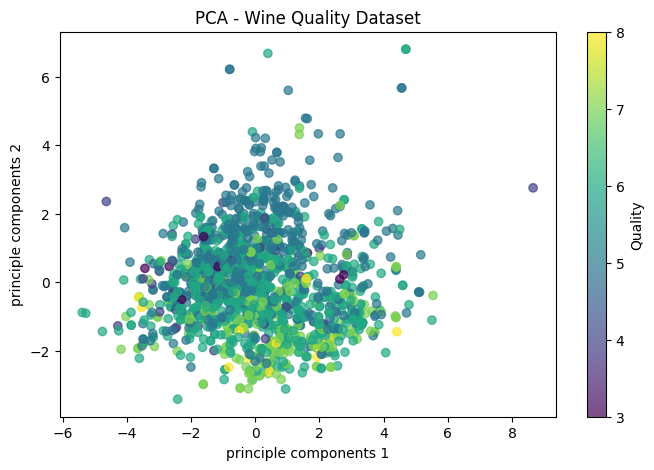

In [30]:
print("\nVariance retained by each component:")
print(pca.explained_variance_ratio_.round(4))
print("Total variance retained:", round(sum(pca.explained_variance_ratio_)*100,2), "%")
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="viridis", alpha=0.7)
plt.xlabel("principle components 1")
plt.ylabel("principle components 2")
plt.title("PCA - Wine Quality Dataset")
plt.colorbar(label="Quality")
plt.show()